<a href="https://colab.research.google.com/github/pilargarlop/Colab-Proyectos/blob/main/K_MEANS_Practica_2_2_Pilar_Garcia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

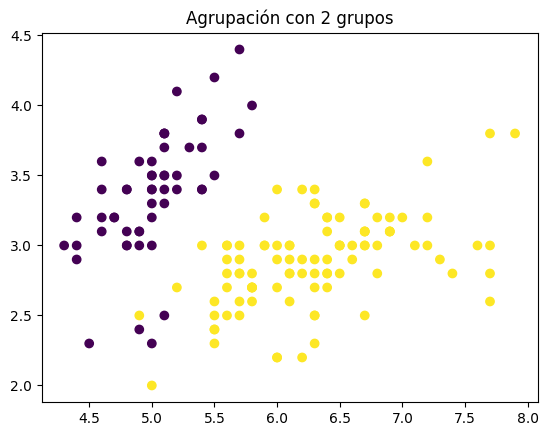

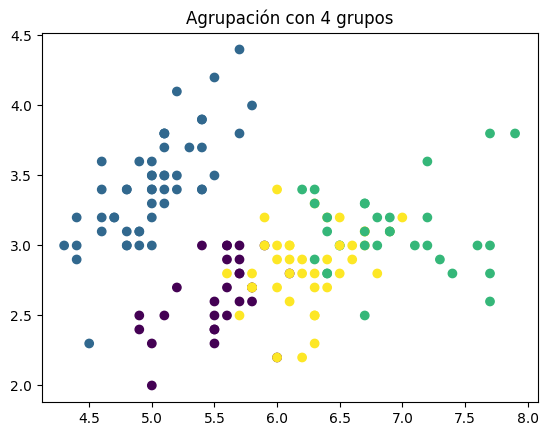

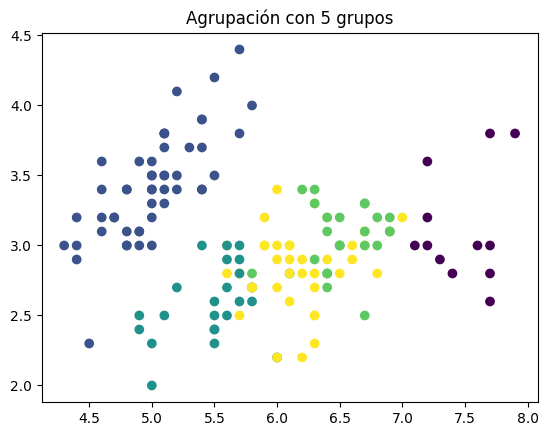

cluster   0   1   2
species            
0         0  50   0
1        48   0   2
2        14   0  36
Total de flores: 150
Fallos totales: 16
Porcentaje de acierto: 89.33 %
setosa -> fallos: 0 de 50 ( 0.0 % )
versicolor -> fallos: 2 de 50 ( 4.0 % )
virginica -> fallos: 14 de 50 ( 28.0 % )
    species_name  cluster_corregido
52    versicolor                  2
77    versicolor                  2
101    virginica                  1
106    virginica                  1
113    virginica                  1
114    virginica                  1
119    virginica                  1
121    virginica                  1
123    virginica                  1
126    virginica                  1
127    virginica                  1
133    virginica                  1
138    virginica                  1
142    virginica                  1
146    virginica                  1
149    virginica                  1


In [6]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()
datos = iris.data

n_clusters = 3
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
modelo.fit(datos)


tabla = pd.DataFrame(datos, columns=iris.feature_names)
tabla['species'] = iris.target
tabla['species_name'] = tabla['species'].map(lambda x: iris.target_names[x])
tabla['cluster'] = modelo.labels_

# ---- probar con 2, 4 y 5 grupos ----
for k in [2, 4, 5]:
    modelo_k = KMeans(n_clusters=k, random_state=0, n_init=10)
    modelo_k.fit(datos)

    plt.scatter(datos[:, 0], datos[:, 1], c=modelo_k.labels_, cmap="viridis")
    plt.title(f"Agrupación con {k} grupos")
    plt.show()

# ---- comparar datos reales con los obtenidos ----

print(pd.crosstab(tabla['species'], tabla['cluster']))

# cluster 1 = setosa, cluster 0 = versicolor, cluster 2 = virginica
equivalencia = {1: 0, 0: 1, 2: 2}
tabla['cluster_corregido'] = tabla['cluster'].map(equivalencia)
tabla['acierto'] = tabla['species'] == tabla['cluster_corregido']

total = len(tabla)
fallos = (~tabla['acierto']).sum()

print("Total de flores:", total)
print("Fallos totales:", fallos)
print("Porcentaje de acierto:", round((total - fallos) / total * 100, 2), "%")


for i in range(3):
    flores = tabla[tabla['species'] == i]
    f = (~flores['acierto']).sum()
    print(iris.target_names[i], "-> fallos:", f, "de", len(flores), "(", round(f / len(flores) * 100, 2), "% )")


print(tabla[~tabla['acierto']][['species_name', 'cluster_corregido']])